# **reconaissance voyelle**

In [11]:
import numpy as np
import msicpe.mana as mana
import msicpe.san as san
import pandas as pd
import msicpe.san as san
from plotly import express as px
import matplotlib.pyplot as plt
import scipy as signal

In [153]:
signal_dict = np.load('data partie 2/apprentissage/o_2.npz') # signal_dict est un dictionnaire
s = signal_dict['s'] # extraction du signal utile
t = signal_dict['t']        

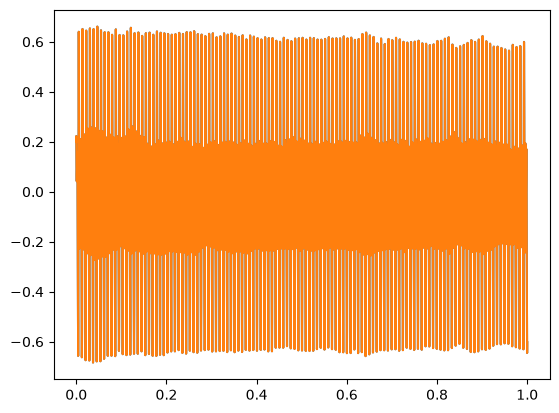

In [154]:
s_centre = s - np.mean(s)
plt.plot(t,s)
plt.plot(t,s_centre)

In [155]:
nu, S = san.trans_fourier(s_centre, t)

spectre = np.abs(S)

df = pd.DataFrame({"nu": nu, "spectre": spectre})

fig = px.line(
    df, 
    x="nu", 
    y=["spectre"], 
    title="Courbe de la fonction"
)
fig.show()

#plt.plot(nu, spectre)

/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


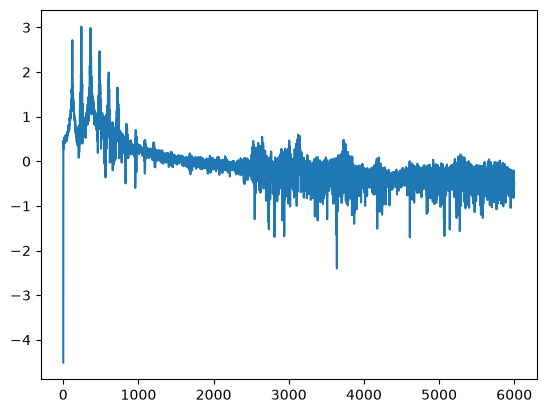

In [156]:
plt.plot(nu, np.log10(S))

In [157]:
help(san.detect_fondamentale)
spectre_norm = spectre/np.max(spectre)

fond = san.detect_fondamentale(spectre_norm,nu)
print(fond)
print(spectre[134])

Help on function detect_fondamentale in module msicpe.san.detect_fondamentale:

detect_fondamentale(spectre, nu, threshold=0.25)
    Fonction permettant de déterminer la fréquence fondamentale d'un signal à partir de son spectre.
    Args:
        spectre (ndarray): spectre du signal
        nu (ndarray): vecteur des fréquences associées au spectre
        threshold (float, optional): seuil pour la détection de la fréquence fondamentale. Default à 0.25.
    Returns:
        nu_fond (float): fréquence fondamentale détectée en Hz

120.95967002777779
13.630949


In [162]:
def vect_signal(chemin, H):
    dat = np.load(chemin)
    s = dat['s']
    t = dat['t']

    s = s - np.mean(s) # centrage du signal

    # Calcul du spectre et normalisation
    nu, sig = san.trans_fourier(s, t)
    spectre = np.abs(sig)
    spectre_norm = spectre / np.max(spectre)

    # Détection de f0
    f0 = san.detect_fondamentale(spectre_norm, nu)

    # Création de la liste des H + 1 fréquences : [f0, 2*f0, ..., (H+1)*f0]
    freq_list = [k * f0 for k in range(1, H + 2)]

    # Extraction des amplitudes des pics
    _, peak_amplitudes = san.detect_pics(spectre_norm, freq_list, nu)

    # Renvoi du vecteur caractéristique en échelle logarithmique (taille H + 1)
    return np.log10(peak_amplitudes)

print(vect_signal('/Users/adel/Documents/code/SAN/Projet SAN/data partie 2/etude/BON_signal_3.npz',11))

[-0.12075384  0.         -1.4711585  -2.3327425  -2.80172    -2.4447694
 -2.6249788  -2.8398972  -2.854561   -2.8098037  -2.9446673  -3.0266018 ]


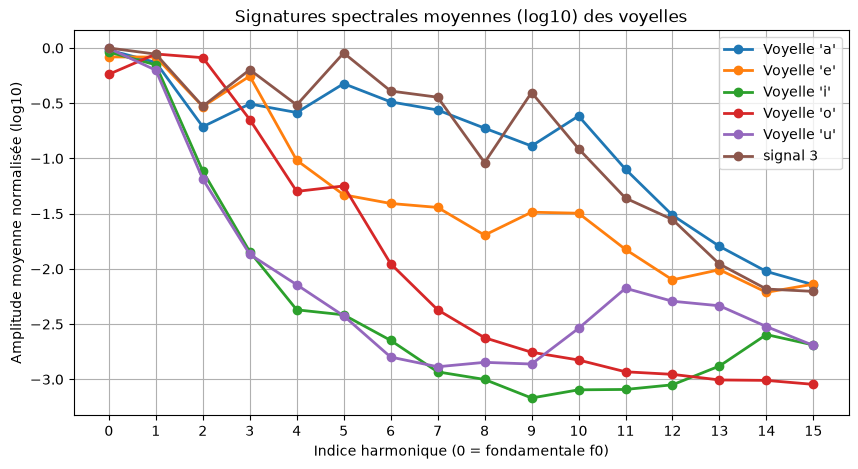

In [167]:
voyelles = ['a', 'e', 'i', 'o', 'u']
H = 15  # Nombre d'harmoniques (vecteur final de dimension H + 1)
nb_sons = 5

base_apprentissage = {}
indices = np.arange(0, H + 1)

plt.figure(figsize=(10, 5))

for v in voyelles:
    vecteurs = np.zeros((nb_sons, H + 1))

    for i in range(1, nb_sons + 1):
        # Adapter le chemin/nom selon tes fichiers (ex: f'apprentissage/{v}_{i}.npz')
        dat = np.load(f'data partie 2/apprentissage/{v}_{i}.npz')
        s = dat['s']
        t = dat['t']

        s = s - np.mean(s) # centrage du signal

        # Calcul du spectre et normalisation
        nu, sig = san.trans_fourier(s, t)
        spectre = np.abs(sig)
        spectre_norm = spectre / np.max(spectre)

        # Détection de f0 (vérifier l'ordre des arguments avec help(san.detect_fondamentale))
        f0 = san.detect_fondamentale(spectre_norm, nu)

        # Création de la liste des H + 1 fréquences : [f0, 2*f0, ..., (H+1)*f0]
        freq_list = [k * f0 for k in range(1, H + 2)]

        # Extraction des amplitudes des pics
        freq_peaks, peak_amplitudes = san.detect_pics(
            spectre_norm, freq_list, nu
        )

        # Stockage en échelle logarithmique (base 10)
        vecteurs[i - 1, :] = np.log10(peak_amplitudes)

    # Calcul et sauvegarde du vecteur moyen pour la voyelle v
    base_apprentissage[v] = np.mean(vecteurs, axis=0)

    # Tracé du vecteur moyen
    plt.plot(
        indices,
        base_apprentissage[v],
        '-o',
        linewidth=2,
        label=f"Voyelle '{v}'",
    )

#plot du signal d'etude 3
plt.plot(
        indices,
        vect_signal('data partie 2/test/a_6.npz',H),
        '-o',
        linewidth=2,
        label="signal 3",
    )

plt.title('Signatures spectrales moyennes (log10) des voyelles')
plt.xlabel('Indice harmonique (0 = fondamentale f0)')
plt.ylabel('Amplitude moyenne normalisée (log10)')
plt.xticks(indices)
plt.grid(True)
plt.legend()
plt.show()